# 17 - Exporter un modele : ONNX verifie, lot dynamique, OpenVINO, latence, carte du modele

Le programme de production (C#, C++, Python sans PyTorch) ne charge que deux fichiers :
`model.onnx` (le reseau) et `model_card.json` (tout ce qu'il faut pour preparer l'image et lire
les sorties). Ce notebook deroule l'export d'un bout a l'autre, sur deux modeles legers :
- un classifieur resnet18 (NEU-CLS), normalisation ImageNet EN DEHORS du graphe (dans la carte) ;
- un segmenteur U-Net resnet18 (Magnetic Tile), normalisation et softmax DANS le graphe.

Ce que l'on apprend :
1. exporter avec `torch.onnx` (exporteur dynamo, puis l'ancien), lot dynamique ;
2. detecter un lot FIGE dans le graphe et se replier sur un lot fixe de 1 ;
3. verifier ONNX contre PyTorch sur de vraies images, avec une tolerance a l'echelle de la sortie
   (un export qui passe sans verification ne vaut rien : un operateur mal traduit ne leve aucune
   erreur, il donne des sorties fausses) ;
4. convertir en OpenVINO (CPU Intel) et mesurer la latence (chauffe, mediane, p95) ;
5. ecrire la carte du modele a la main, champ par champ.

Donnees : `python tools/get_data/get_neu_cls.py` et `get_magnetic_tile.py`. Prerequis : extras
`segmentation` (segmentation_models_pytorch) et `export` (OpenVINO, facultatif).
Duree en mode QUICK sur un CPU 2 coeurs : 2 a 3 minutes. Lancer depuis la racine du depot.
Les deux dossiers exportes (`OUT/classifier`, `OUT/segmenter`) servent au notebook 18.

**Dans le fil** : ce notebook approfondit l'etape 12 (Sauvegarder et exporter).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 0. Reglages

In [1]:
import contextlib  # contextlib : outils pour les blocs "with" (ici : faire taire les affichages des exporteurs)
import copy  # copy : copie complete d'un objet (deepcopy), pour experimenter sans abimer l'original
import inspect  # inspect : lire la signature d'une fonction (le nom de ses arguments)
import io  # io : "fichiers" en memoire (StringIO), ici pour avaler le texte affiche par les exporteurs
import json  # json : ecrire et lire la carte du modele (fichier texte structure)
import platform  # platform : version de Python, notee dans la carte du modele
import time  # time : chronometre, pour mesurer la latence (temps de reponse)
import warnings  # warnings : masquer les avertissements trop bavards
from datetime import UTC, datetime  # date et heure ; UTC = temps universel (independant du fuseau horaire)
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnx  # onnx : lire et inspecter un fichier .onnx (ONNX = format standard de reseau, lisible sans PyTorch)
import onnxruntime as ort  # ONNX Runtime : le moteur qui execute un modele .onnx (celui qu'utilise la production)
import pandas as pd  # pandas : tableaux de donnees (DataFrame)
import segmentation_models_pytorch as smp  # reseaux de segmentation prets a l'emploi (U-Net, etc.)
import torch  # PyTorch : tenseurs (tableaux de nombres sur CPU ou GPU) et reseaux de neurones
import torch.nn as nn  # nn : les briques des reseaux (couches, modules)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.linear_model import LogisticRegression  # regression logistique : classifieur lineaire simple et rapide
from torchvision import models  # modeles de vision pre-entraines (resnet18...)

from vtb import viz  # module d'affichage de la toolbox (figures, graphiques de latence)

QUICK = True  # True : peu d'images pour la tete du classifieur et les mesures ; False : plus d'images
SEED = 0  # graine du hasard : memes tirages a chaque execution
CLASS_DIR = Path("data/raw/neu_cls_flat")  # un sous-dossier par classe
TILE_DIR = Path("data/raw/magnetic_tile/MT_Crack/Imgs")  # images pour verifier le segmenteur
IMAGE_SIZE = 128  # images en 128 x 128, comme la recette (resnet18_head.yaml, unet_resnet18_tile_cpu.yaml)
PER_CLASS_TRAIN = 40 if QUICK else 200  # images par classe pour apprendre la tete du classifieur
PER_CLASS_TEST = 20 if QUICK else 60  # images par classe pour mesurer l'exactitude
OPSET = 18  # opset = version de l'ensemble d'operateurs ONNX ; le moteur de production doit la connaitre
ATOL, RTOL = 1e-4, 1e-3  # tolerance de verification : atol + rtol x (valeur max de la sortie)
LATENCY_RUNS = 20 if QUICK else 100  # nombre de passages chronometres pour mesurer la latence
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # moyenne et ecart-type R, G, B d'ImageNet
torch.manual_seed(SEED)  # fixe le hasard de PyTorch (poids initiaux) : resultats reproductibles
OUT = Path("outputs/notebooks/17_export_onnx")  # dossier de sortie du notebook
CLASSIFIER_DIR, SEGMENTER_DIR = OUT / "classifier", OUT / "segmenter"  # un dossier par modele exporte (relus par le notebook 18)
for folder in (CLASSIFIER_DIR, SEGMENTER_DIR):  # pour chacun des deux dossiers
    folder.mkdir(parents=True, exist_ok=True)  # le creer (et ses parents) ; pas d'erreur s'il existe deja
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en 80 points par pouce et en JPEG : notebook plus leger
warnings.filterwarnings("ignore", category=UserWarning)  # masque les avertissements d'usage (nombreux pendant l'export)
warnings.filterwarnings("ignore", category=DeprecationWarning)  # masque les annonces de fonctions bientot retirees


def list_images(folder: Path, extensions: tuple[str, ...] = (".bmp", ".jpg", ".png")) -> list[Path]:  # images d'un dossier
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in extensions)  # sous-dossiers compris, triees


def read_image(path: str | Path, color: str = "rgb") -> np.ndarray:  # lit une image en RGB (3 canaux) ou en gris
    """Lecture robuste ; color = rgb (gris copie sur 3 canaux) ou gray. Meme convention que la production."""
    image = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_UNCHANGED)  # octets du fichier -> image (accents acceptes)
    if color == "gray":  # lecture demandee en niveaux de gris
        return cv2.cvtColor(image[..., :3], cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; gris inchangee
    # gris -> copie sur 3 canaux ; couleur : BGR (ordre d'OpenCV) -> RGB (ordre attendu par le reseau)
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image[..., :3], cv2.COLOR_BGR2RGB)


def resize_auto(image: np.ndarray, size: int) -> np.ndarray:  # redimensionne en carre size x size, interpolation adaptee
    """INTER_AREA pour reduire, INTER_LINEAR pour agrandir : l'operation `resize` (interpolation auto) de la carte."""
    flag = cv2.INTER_AREA if size * size < image.shape[0] * image.shape[1] else cv2.INTER_LINEAR  # AREA si on reduit
    return cv2.resize(image, (size, size), interpolation=flag)  # redimensionne avec l'interpolation choisie

## 1. Deux modeles legers a exporter

**Classifieur** : resnet18 ImageNet, tete neuve a 6 classes. Pour aller vite, la tete est une
regression logistique apprise sur les plongements geles, recopiee dans la couche `fc` (memes
logits, a l'arrondi pres). L'entrainement complet est le sujet des notebooks 06 et 07 ; ici, seul
l'export compte. La normalisation ImageNet reste HORS du graphe : la carte la decrit (mean / std).

**Segmenteur** : U-Net resnet18 (segmentation_models_pytorch), encodeur ImageNet, decodeur non
entraine (l'export ne depend pas de la valeur des poids ; entrainement : notebook 12). Il prend
une image grise dans [0, 1] : la copie sur 3 canaux, la normalisation ImageNet et le softmax sont
DANS le graphe. Le programme de production n'a alors rien a normaliser.

In [2]:
catalog = pd.DataFrame(  # catalogue des images : une ligne par image (chemin, classe)
    # pour chaque sous-dossier de classe (trie), pour chaque image : {chemin, nom de la classe}
    [{"path": str(p), "label": d.name} for d in sorted(x for x in CLASS_DIR.iterdir() if x.is_dir()) for p in list_images(d)]
)
# tire au hasard (graine SEED) train + test images dans chaque classe ; group_keys=False : pas de niveau d'index en plus
catalog = catalog.groupby("label", group_keys=False).sample(n=PER_CLASS_TRAIN + PER_CLASS_TEST, random_state=SEED)
# cumcount numerote les images de chaque classe (0, 1, 2...) : les PER_CLASS_TRAIN premieres en train, les autres en test
catalog["split"] = np.where(catalog.groupby("label").cumcount() < PER_CLASS_TRAIN, "train", "test")
CLASS_NAMES = sorted(catalog["label"].unique())  # noms des classes tries : la position d'un nom = son numero de classe


def classifier_input(paths: list[str]) -> torch.Tensor:  # chemins d'images -> tenseur pret pour le classifieur
    """Lecture RGB -> resize 128 -> [0, 1] -> normalisation ImageNet -> NCHW : exactement ce que dira la carte."""
    # lot (batch) = plusieurs images empilees : lecture RGB, 128 x 128, puis valeurs ramenees dans [0, 1]
    batch = np.stack([resize_auto(read_image(p, "rgb"), IMAGE_SIZE) for p in paths]).astype(np.float32) / 255.0
    # normalisation ImageNet : chaque canal moins sa moyenne, divise par son ecart-type (comme a l'entrainement d'origine)
    batch = (batch - np.array(IMAGENET_MEAN, np.float32)) / np.array(IMAGENET_STD, np.float32)
    # (lot, hauteur, largeur, canaux) -> NCHW = (lot, canaux, hauteur, largeur), l'ordre de PyTorch ; copy() : memoire contigue
    return torch.from_numpy(batch.transpose(0, 3, 1, 2).copy())


classifier = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)  # resnet18 pre-entraine sur ImageNet
classifier.fc = nn.Identity()  # retire la derniere couche : le reseau sort ses plongements (512 nombres par image)
classifier.eval()  # mode evaluation : BatchNorm et Dropout figes (comportement de production)
with torch.no_grad():  # sans calcul de gradient (inutile hors entrainement) : plus rapide, moins de memoire
    # plongements des images de train et de test, convertis en tableaux numpy (un dict par split)
    features = {s: classifier(classifier_input(catalog.loc[catalog["split"] == s, "path"].tolist())).numpy() for s in ("train", "test")}
# numero de classe de chaque image (position du nom dans CLASS_NAMES), pour train et test
labels = {s: catalog.loc[catalog["split"] == s, "label"].map(CLASS_NAMES.index).to_numpy() for s in ("train", "test")}
head = LogisticRegression(C=1.0, max_iter=3000).fit(features["train"], labels["train"])  # apprend la tete sur les plongements
classifier.fc = nn.Linear(512, len(CLASS_NAMES))  # nouvelle derniere couche : 512 plongements -> 6 logits (scores bruts)
with torch.no_grad():  # copie de poids : PyTorch ne doit pas la suivre pour un gradient
    classifier.fc.weight.copy_(torch.from_numpy(head.coef_).float())  # poids de la regression copies dans fc (meme calcul W x + b)
    classifier.fc.bias.copy_(torch.from_numpy(head.intercept_).float())  # biais copies aussi
classifier.eval()  # de nouveau en mode evaluation (la nouvelle couche comprise)
test_paths = catalog.loc[catalog["split"] == "test", "path"].tolist()  # chemins des images de test
with torch.no_grad():  # inference sans gradient
    test_logits = classifier(classifier_input(test_paths)).numpy()  # logits du test (scores avant softmax), en numpy
accuracy = float((test_logits.argmax(1) == labels["test"]).mean())  # exactitude : part des images ou le plus grand logit est juste
print(f"classifieur : exactitude sur {len(test_paths)} images de test = {accuracy:.3f}")  # affiche l'exactitude


class Segmenter(nn.Module):  # enveloppe du U-Net : met la normalisation et le softmax DANS le reseau exporte
    """Gris [0, 1] (N, 1, H, W) -> probabilites par classe et par pixel (N, C, H, W)."""

    def __init__(self, net: nn.Module) -> None:  # construit l'enveloppe autour du reseau net
        super().__init__()  # initialise la partie nn.Module (obligatoire)
        self.net = net  # le U-Net enveloppe
        # buffer : tenseur fixe, sauve et exporte avec le modele ; forme (1, 3, 1, 1) : s'applique a chaque pixel de chaque image
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))  # ecart-type ImageNet, meme forme

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # passe avant : gris (N, 1, H, W) -> probabilites (N, 2, H, W)
        x = x.repeat(1, 3, 1, 1)  # le gris copie sur 3 canaux : la reponse des poids ImageNet est exacte
        # normalise, passe dans le U-Net, puis softmax sur les classes (dim=1) : des probabilites qui somment a 1
        return torch.softmax(self.net((x - self.mean) / self.std), dim=1)


unet = smp.Unet("resnet18", encoder_weights=None, in_channels=3, classes=2)  # U-Net, encodeur resnet18, 2 classes (fond, defaut)
imagenet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1).state_dict()  # poids ImageNet (dict nom -> tenseur)
# encodeur resnet18 ImageNet : tous les poids sauf la couche fc (l'encodeur n'en a pas)
unet.encoder.load_state_dict({k: v for k, v in imagenet.items() if not k.startswith("fc.")})  # encodeur resnet18 ImageNet
segmenter = Segmenter(unet).eval()  # l'enveloppe, en mode evaluation
tile_paths = [str(p) for p in list_images(TILE_DIR, (".jpg",))][:12]  # 12 images de fissures pour verifier le segmenteur
tile_batch = torch.from_numpy(  # lot de tuiles : tenseur (12, 1, 128, 128) dans [0, 1]
    # lecture en gris, 128 x 128 ; [:, None] ajoute l'axe des canaux ; / 255 ramene dans [0, 1]
    np.stack([resize_auto(read_image(p, "gray"), IMAGE_SIZE) for p in tile_paths]).astype(np.float32)[:, None] / 255.0
)
print(  # affiche le nombre de parametres (en millions) et la forme de la sortie pour 2 images
    f"segmenteur : {sum(p.numel() for p in segmenter.parameters()) / 1e6:.1f} M parametres, sortie {tuple(segmenter(tile_batch[:2]).shape)}"
)

classifieur : exactitude sur 120 images de test = 0.983


segmenteur : 14.3 M parametres, sortie (2, 2, 128, 128)


## 2. Exporter avec un lot dynamique

Deux exporteurs dans `torch.onnx` :
- **dynamo** (`dynamo=True`, recommande) : capture le graphe par `torch.export` ; la dimension du
  lot est declaree dynamique par `dynamic_shapes` ;
- **ancien** (`dynamo=False`, TorchScript) : trace le modele avec un exemple ; `dynamic_axes`
  declare le lot dynamique. Plus permissif, utile quand dynamo refuse un modele.

Dans les deux cas on VERIFIE que le modele tourne vraiment avec un autre lot que l'exemple : une
forme declaree dynamique peut cacher un `reshape` qui a fige la taille du lot. En dernier recours,
on exporte avec un lot fixe de 1 (le programme de production envoie alors les images une par une).

In [3]:
# exporte un modele PyTorch en fichier ONNX (graphe de calcul fige), avec l'exporteur dynamo ou l'ancien
def _export(model: nn.Module, example: torch.Tensor, path: Path, output_names: list[str], dynamic: bool, dynamo: bool) -> None:
    # redirige ce que les exporteurs affichent vers des tampons en memoire, jamais lus
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):  # les exporteurs sont bavards
        if dynamo:  # exporteur dynamo (recommande)
            first_arg = next(iter(inspect.signature(model.forward).parameters))  # nom de l'argument d'entree de forward
            shapes = {first_arg: {0: torch.export.Dim("batch", min=1, max=1024)}} if dynamic else None  # dim 0 (lot) libre, 1 a 1024
            torch.onnx.export(  # ecrit le fichier .onnx
                model,  # le modele a exporter
                (example,),  # un exemple d'entree (tuple des arguments de forward)
                str(path),  # le fichier .onnx a ecrire
                input_names=["input"],  # nom de l'entree dans le graphe
                output_names=output_names,  # noms des sorties dans le graphe
                dynamic_shapes=shapes,  # dimensions dynamiques (ici le lot) ; None = tout fixe
                dynamo=True,  # choisit l'exporteur dynamo
                external_data=False,  # poids DANS le .onnx (pas de fichier de donnees a cote)
                opset_version=OPSET,  # version des operateurs ONNX
            )
        else:  # sinon : ancien exporteur (TorchScript, par trace de l'exemple)
            # dimension 0 nommee "batch" (donc dynamique) pour l'entree et pour chaque sortie ; None = fixe
            axes = {"input": {0: "batch"}, **{n: {0: "batch"} for n in output_names}} if dynamic else None
            torch.onnx.export(  # ecrit le fichier .onnx
                model,  # le modele a exporter
                (example,),  # l'exemple suivi pendant la trace
                str(path),  # le fichier .onnx a ecrire
                input_names=["input"],  # nom de l'entree
                output_names=output_names,  # noms des sorties
                dynamic_axes=axes,  # axes dynamiques (syntaxe de l'ancien exporteur)
                opset_version=OPSET,  # version des operateurs ONNX
                dynamo=False,  # force l'ancien exporteur
            )


def session(path: Path) -> ort.InferenceSession:  # ouvre un modele ONNX ; renvoie la session (le moteur pret a calculer)
    return ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])  # execution sur CPU


def batch_size_of(path: Path) -> int | None:  # renvoie la taille de lot figee dans le graphe, ou None
    """Taille de lot imposee par le graphe ONNX, None si dynamique."""
    dim = session(path).get_inputs()[0].shape[0]  # 1re dimension de l'entree : un entier (fige) ou un nom ("batch")
    return dim if isinstance(dim, int) else None  # entier -> lot fige ; texte -> lot dynamique (None)


def accepts_batch(path: Path, example: torch.Tensor, n: int) -> bool:  # vrai si le modele tourne vraiment avec n images
    try:  # tout echec ci-dessous veut dire "non"
        if batch_size_of(path) not in (None, n):  # lot fige a une autre taille que n
            return False  # refuse d'office
        s = session(path)  # ouvre le modele
        # n copies de la 1re image (repeat sur l'axe du lot) ; None = calculer toutes les sorties ; entree en numpy
        outputs = s.run(None, {s.get_inputs()[0].name: example[:1].repeat(n, *([1] * (example.ndim - 1))).numpy()})
        return all(o.shape[0] == n for o in outputs)  # un reshape fige peut TOURNER et rendre une sortie de mauvaise taille
    except Exception:  # noqa: BLE001 - tout echec veut dire "lot non dynamique"
        return False  # le lot n'est pas dynamique


def export_onnx(model: nn.Module, example: torch.Tensor, path: Path, output_names: list[str]) -> dict:  # exporte, verifie le lot
    """dynamo puis ancien exporteur, lot dynamique verifie ; sinon lot fixe de 1. Renvoie le journal des essais."""
    model = model.eval().cpu()  # mode evaluation, sur CPU (l'export se fait sur CPU)
    attempts = []  # journal des essais, en texte
    for dynamo in (True, False):  # essaie dynamo d'abord, puis l'ancien exporteur
        name = "dynamo" if dynamo else "ancien"  # nom lisible de l'exporteur
        start = time.perf_counter()  # chronometre
        try:  # l'export peut echouer
            _export(model, example, path, output_names, dynamic=True, dynamo=dynamo)  # export avec lot dynamique
        except Exception as error:  # noqa: BLE001 - on veut la cause et on passe a l'exporteur suivant
            attempts.append(f"{name} : echec ({type(error).__name__}: {str(error).splitlines()[0][:90]})")  # type + debut du message
            continue  # passe a l'exporteur suivant
        if accepts_batch(path, example, len(example) + 1):  # le modele accepte-t-il un lot d'une AUTRE taille que l'exemple ?
            attempts.append(f"{name} : OK, lot dynamique ({time.perf_counter() - start:.1f} s)")  # succes, avec la duree
            return {"exporter": name, "dynamic_batch": True, "attempts": attempts}  # exporteur retenu, lot dynamique, journal
        attempts.append(f"{name} : le lot reste fige dans le graphe")  # export reussi mais lot fige : on essaie le suivant
    _export(model, example[:1], path, output_names, dynamic=False, dynamo=False)  # dernier recours : lot fixe d'une image
    attempts.append("ancien, lot FIXE de 1 : le programme de production envoie les images une par une")  # note le repli
    return {"exporter": "ancien", "dynamic_batch": False, "attempts": attempts}  # lot fixe


exports = {  # exporte les deux modeles et garde le journal de chacun
    # classifieur : exemple de 2 images de test, une sortie nommee "logits"
    "classifier": export_onnx(classifier, classifier_input(test_paths[:2]), CLASSIFIER_DIR / "model.onnx", ["logits"]),
    "segmenter": export_onnx(segmenter, tile_batch[:2], SEGMENTER_DIR / "model.onnx", ["probabilities"]),  # segmenteur : 2 tuiles
}
for name, report in exports.items():  # pour chaque modele exporte
    print(name, "|", " ; ".join(report["attempts"]))  # affiche son journal d'essais sur une ligne

classifier | dynamo : OK, lot dynamique (2.3 s)
segmenter | dynamo : OK, lot dynamique (3.0 s)


Ce qu'il y a dans le fichier : entrees, sorties (avec la dimension `batch` symbolique), version
d'opset, et les operateurs les plus frequents. C'est aussi le premier reflexe quand un programme
de production refuse un modele : un operateur absent de sa version d'ONNX Runtime.

In [4]:
def describe(path: Path) -> dict:  # resume un fichier ONNX : taille, opset, entree, sorties, operateurs ; renvoie un dict
    model = onnx.load(str(path))  # charge le graphe ONNX (sans l'executer)

    def shape(value: onnx.ValueInfoProto) -> list:  # forme d'une entree ou d'une sortie, dimension par dimension
        return [d.dim_param or d.dim_value for d in value.type.tensor_type.shape.dim]  # nom si dynamique ("batch"), sinon entier

    ops = pd.Series([n.op_type for n in model.graph.node]).value_counts()  # type de chaque operation (Conv, Relu...) compte et trie
    return {  # le resume
        "taille (Mo)": round(path.stat().st_size / 1e6, 1),  # taille du fichier en megaoctets
        "opset": model.opset_import[0].version,  # version des operateurs
        "entree": f"{model.graph.input[0].name} {shape(model.graph.input[0])}",  # nom et forme de l'entree
        "sorties": ", ".join(f"{o.name} {shape(o)}" for o in model.graph.output),  # nom et forme de chaque sortie
        "noeuds": len(model.graph.node),  # nombre d'operations (noeuds) du graphe
        "operateurs frequents": ", ".join(f"{k} x{v}" for k, v in ops.head(5).items()),  # les 5 operateurs les plus frequents
    }


display(  # affiche le resume des deux fichiers
    # tableau : une colonne par modele (classifieur, segmenteur)
    pd.DataFrame({name: describe(folder / "model.onnx") for name, folder in (("classifier", CLASSIFIER_DIR), ("segmenter", SEGMENTER_DIR))})
)

,classifier,segmenter
taille (Mo),44.8,57.5
opset,18,18
entree,"input ['batch', 3, 128, 128]","input ['batch', 1, 128, 128]"
sorties,"logits ['batch', 6]","probabilities ['batch', 2, 128, 128]"
noeuds,49,91
operateurs frequents,"Conv x20, Relu x17, Add x8, MaxPool x1, Reduce...","Conv x31, Relu x27, Concat x9, Add x8, Shape x5"


## 3. Un lot fige, detecte et contourne

Le cas classique : `n = int(x.shape[0])` dans `forward` (ou un `view(2, -1)` ecrit en dur).
Les deux exporteurs "reussissent", mais figent le lot de l'exemple (2) dans un `Reshape`. Selon
les tailles, le modele plante des qu'on change de lot... ou PIRE, il tourne et rend une sortie de
mauvaise taille (ici 2 valeurs pour 3 images : 3 x 1024 valeurs se redecoupent en 2 x 1536).
La fonction d'export verifie donc aussi la taille du lot en SORTIE, puis se replie sur un lot
fixe de 1. Certains modeles reels figent le lot (PatchCore et DFM d'anomalib) : la carte le dit
(`dynamic_batch: false`) et la verification passe les images par paquets de 1.

In [5]:
class FrozenBatch(nn.Module):  # petit modele piege : sa taille de lot se fige a l'export
    def __init__(self) -> None:  # construit le modele
        super().__init__()  # initialise la partie nn.Module
        self.conv = nn.Conv2d(1, 4, 3, padding=1)  # une convolution : 1 canal -> 4, noyau 3 x 3, meme taille en sortie

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # passe avant : une valeur par image
        n = int(x.shape[0])  # int() : la taille du lot devient une constante pendant la capture
        return self.conv(x).reshape(n, -1).mean(dim=1)  # reshape avec n fige (le piege), puis moyenne par image


frozen_path = OUT / "frozen_batch.onnx"  # fichier ONNX du modele piege
frozen = FrozenBatch().eval()  # le modele, en mode evaluation
frozen_report = export_onnx(frozen, torch.rand(2, 1, 16, 16), frozen_path, ["score"])  # export avec 2 images aleatoires 16 x 16
print("\n".join(frozen_report["attempts"]))  # affiche le journal, un essai par ligne
print("taille de lot imposee par le graphe :", batch_size_of(frozen_path))  # 1 apres le repli sur un lot fixe

dynamo : le lot reste fige dans le graphe
ancien : le lot reste fige dans le graphe
ancien, lot FIXE de 1 : le programme de production envoie les images une par une
taille de lot imposee par le graphe : 1


## 4. Verifier ONNX contre PyTorch

Sur de VRAIES images, avec un lot d'une autre taille que celui de l'export (le lot dynamique est
ainsi teste aussi). Echec si l'ecart maximal depasse `atol + rtol x (valeur max de la sortie)` :
la tolerance suit l'ECHELLE de la sortie (une distance pres de zero et un logit de 10 n'ont pas la
meme precision absolue). Un vrai defaut d'export donne des ecarts de l'ordre de la sortie elle-meme,
des milliers de fois au-dessus.

In [6]:
class OnnxVerificationError(RuntimeError):  # erreur levee quand ONNX et PyTorch ne donnent pas le meme resultat
    pass  # aucun code en plus : seul le nom de l'erreur compte (on peut l'attraper a part)


@torch.no_grad()  # decorateur : toute la fonction s'execute sans gradient
# compare les sorties ONNX et PyTorch sur un lot ; renvoie un rapport des ecarts, ou leve OnnxVerificationError
def verify_onnx(model: nn.Module, path: Path, batch: torch.Tensor, atol: float = ATOL, rtol: float = RTOL) -> dict:
    reference = model(batch)  # sortie PyTorch : la reference
    reference = [reference] if isinstance(reference, torch.Tensor) else list(reference)  # toujours une liste de sorties
    s, fixed = session(path), batch_size_of(path)  # session ONNX, et taille de lot figee eventuelle
    name = s.get_inputs()[0].name  # nom de l'entree du graphe
    if fixed is None:  # lot dynamique
        outputs = s.run(None, {name: batch.numpy()})  # tout le lot en une fois ; l'entree passe en numpy
    else:  # lot fige : par paquets de la taille imposee, puis recollage
        chunks = [s.run(None, {name: batch[i : i + fixed].numpy()}) for i in range(0, len(batch), fixed)]  # paquets de `fixed` images
        outputs = [np.concatenate([c[k] for c in chunks]) for k in range(len(chunks[0]))]  # recolle les morceaux de chaque sortie k
    report = {"lot": len(batch)}  # rapport : taille du lot teste
    for k, (t, o) in enumerate(zip(reference, outputs)):  # pour chaque sortie k : t = PyTorch, o = ONNX
        t = t.numpy()  # tenseur PyTorch -> tableau numpy
        if t.shape != o.shape:  # formes differentes : l'export est faux
            raise OnnxVerificationError(f"sortie {k} : forme {o.shape} au lieu de {t.shape}")  # on arrete avec un message clair
        diff, scale = float(np.abs(t - o).max()), float(np.abs(t).max())  # plus grand ecart, et echelle de la sortie
        report[f"sortie {k} : ecart max"] = diff  # note l'ecart
        report[f"sortie {k} : echelle"] = scale  # note l'echelle
        if diff > atol + rtol * scale:  # ecart au-dela de la tolerance
            raise OnnxVerificationError(f"sortie {k} : ecart max {diff:.2e} pour une echelle {scale:.2e}")  # verification echouee
    return report  # tout est conforme


verification = {  # verifie les trois modeles, avec des lots d'une autre taille que l'exemple de l'export
    "classifier": verify_onnx(classifier, CLASSIFIER_DIR / "model.onnx", classifier_input(test_paths[:7])),  # 7 vraies images
    "segmenter": verify_onnx(segmenter, SEGMENTER_DIR / "model.onnx", tile_batch[:5]),  # 5 tuiles
    "frozen_batch (lot fixe de 1, par paquets)": verify_onnx(frozen, frozen_path, torch.rand(3, 1, 16, 16)),  # 3 images aleatoires
}
display(pd.DataFrame(verification).T)  # tableau : une ligne par modele

,lot,sortie 0 : ecart max,sortie 0 : echelle
classifier,7.0,0.000007,9.207498
segmenter,5.0,0.000002,0.765025
"frozen_batch (lot fixe de 1, par paquets)",3.0,0.000000,0.129759


Le piege le plus courant : comparer avec un modele reste en mode `train()`. La BatchNorm utilise
alors les statistiques du lot (et le Dropout tire au hasard) : PyTorch ne donne plus la meme
reponse que le modele exporte (toujours en mode evaluation). La verification l'attrape.
Pire : en mode `train()`, chaque passage MET A JOUR les statistiques de la BatchNorm, meme sous
`torch.no_grad()` : le modele est modifie pour de bon. D'ou la demonstration sur une COPIE.

In [7]:
trap = copy.deepcopy(classifier).train()  # COPIE du classifieur, mise en mode entrainement (le piege)
try:  # on s'attend a un echec de la verification
    verify_onnx(trap, CLASSIFIER_DIR / "model.onnx", classifier_input(test_paths[:7]))  # copie en mode train contre le .onnx
    print("verification passee (inattendu)")  # ne devrait pas arriver
except OnnxVerificationError as error:  # l'echec attendu
    print("verification en echec, comme attendu :", error)  # affiche le message de l'erreur

verification en echec, comme attendu : sortie 0 : ecart max 1.37e+01 pour une echelle 6.17e+00


## 5. OpenVINO et latence

OpenVINO (Intel) convertit le modele ONNX en sa representation (`model.xml` + `model.bin`) et
l'execute souvent 2 a 4 fois plus vite qu'onnxruntime sur CPU Intel. On verifie aussi la
conversion (ecart avec onnxruntime), puis on mesure la latence : deux passages de chauffe (les
premiers sont lents : allocation, compilation), puis la mediane et le 95e centile sur
`LATENCY_RUNS` passages, pour un lot de 1 (une piece a la fois) et de 8.

Piege : sur les CPU recents (instructions AMX ou AVX512-BF16), OpenVINO calcule PAR DEFAUT en
bfloat16 : 2 a 4 fois plus rapide, mais des ecarts de l'ordre de 1e-2 a 1e-1 sur les sorties.
`{"INFERENCE_PRECISION_HINT": "f32"}` reduit l'ecart d'un ordre de grandeur (sans retrouver
exactement onnxruntime : autres algorithmes de convolution). Le bon critere n'est donc pas
l'ecart brut mais la DECISION : meme classe predite, memes pixels de defaut. On le mesure.

classifier : OpenVINO precision par defaut <Type: 'bfloat16'> -> ecart max / onnxruntime 1.4e-01 (meme classe predite : 100%) ; en f32 : 1.6e-02


segmenter : OpenVINO precision par defaut <Type: 'bfloat16'> -> ecart max / onnxruntime 2.8e-02 (memes pixels de defaut : 97.91%) ; en f32 : 3.7e-03


moteur          onnxruntime  openvino  openvino f32   torch
modele     lot                                             
classifier 1           4.36      1.36          4.50   10.08
           8          33.24      7.21         36.33   47.43
segmenter  1          12.07      3.02         11.36   23.43
           8          93.11     24.97         79.91  113.07

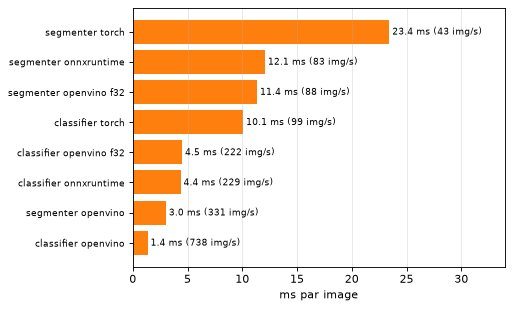

In [8]:
try:  # OpenVINO est facultatif : on continue sans lui s'il manque
    import openvino as ov  # OpenVINO : moteur d'inference d'Intel, rapide sur CPU Intel

    core = ov.Core()  # point d'entree d'OpenVINO
    compiled, compiled_f32 = {}, {}  # modeles compiles : precision par defaut, et forcee en float32
    for name, folder in (("classifier", CLASSIFIER_DIR), ("segmenter", SEGMENTER_DIR)):  # pour chaque modele
        ov.save_model(ov.convert_model(str(folder / "model.onnx")), str(folder / "model.xml"))  # .onnx -> model.xml + model.bin
        compiled[name] = core.compile_model(str(folder / "model.xml"), "CPU")  # precision par defaut du CPU
        compiled_f32[name] = core.compile_model(str(folder / "model.xml"), "CPU", {"INFERENCE_PRECISION_HINT": "f32"})  # force f32
except ImportError:  # OpenVINO n'est pas installe
    compiled, compiled_f32 = {}, {}  # aucun modele OpenVINO
    print("OpenVINO absent (extra export) : mesures onnxruntime seulement")  # previent l'utilisateur


def timed(fn, runs: int = LATENCY_RUNS) -> dict:  # chronometre fn ; renvoie la mediane (p50) et le 95e centile (p95) en ms
    for _ in range(2):  # deux passages de chauffe, non mesures
        fn()  # les premiers passages sont lents (allocation, compilation)
    times = []  # durees mesurees (ms)
    for _ in range(runs):  # passages mesures
        start = time.perf_counter()  # top depart
        fn()  # le calcul a mesurer
        times.append(1000 * (time.perf_counter() - start))  # duree en millisecondes
    # p50 = mediane (temps typique) ; p95 = 95 % des passages sont plus rapides (les pires cas)
    return {"p50_ms": float(np.median(times)), "p95_ms": float(np.percentile(times, 95))}


latency_rows, latency = [], {}  # lignes du tableau de latence ; latence p50 a lot 1, par "modele moteur"
for name, model, folder, example in (  # pour chaque modele : nom, modele PyTorch, dossier exporte, lot de 8 images
    ("classifier", classifier, CLASSIFIER_DIR, classifier_input(test_paths[:8])),  # classifieur et 8 images de test
    ("segmenter", segmenter, SEGMENTER_DIR, tile_batch[:8]),  # segmenteur et 8 tuiles
):
    s = session(folder / "model.onnx")  # session ONNX Runtime
    for batch in (1, 8):  # lot d'une image (une piece a la fois), puis de 8
        x = example[:batch]  # les `batch` premieres images
        runners = {  # une fonction sans argument par moteur a chronometrer
            "torch": lambda model=model, x=x: model(x),  # PyTorch ; model=model fige la valeur courante dans la lambda
            "onnxruntime": lambda s=s, x=x: s.run(None, {"input": x.numpy()}),  # ONNX Runtime, entree en numpy
        }
        if name in compiled:  # si OpenVINO est disponible
            runners["openvino"] = lambda engine=compiled[name], x=x: engine(x.numpy())  # OpenVINO, precision par defaut
            runners["openvino f32"] = lambda engine=compiled_f32[name], x=x: engine(x.numpy())  # OpenVINO force en float32
        with torch.no_grad():  # PyTorch sans gradient
            for engine, fn in runners.items():  # pour chaque moteur
                result = timed(fn)  # mesure sa latence
                # une ligne : modele, lot, moteur, p50 et p95 arrondis a 2 decimales
                latency_rows.append({"modele": name, "lot": batch, "moteur": engine, **{k: round(v, 2) for k, v in result.items()}})
                if batch == 1:  # pour le lot d'une image
                    latency[f"{name} {engine}"] = result["p50_ms"]  # garde la mediane (pour la carte et le graphique)
    if name in compiled:  # comparaison OpenVINO / onnxruntime
        ort_out = s.run(None, {"input": example.numpy()})[0]  # sortie ONNX Runtime sur le lot de 8
        precision = compiled[name].get_property("INFERENCE_PRECISION_HINT")  # precision choisie par OpenVINO (bf16 ou f32)
        gap_default = np.abs(ort_out - compiled[name](example.numpy())[0]).max()  # plus grand ecart, precision par defaut
        gap_f32 = np.abs(ort_out - compiled_f32[name](example.numpy())[0]).max()  # plus grand ecart, en float32
        if name == "classifier":  # classifieur : la decision est la classe predite
            same = float((ort_out.argmax(1) == compiled[name](example.numpy())[0].argmax(1)).mean())  # part de classes identiques
            decision = f"meme classe predite : {same:.0%}"  # texte du resultat (:.0% = pourcentage sans decimale)
        else:  # segmenteur : la decision est le masque de defaut
            # part des pixels avec la meme decision des deux cotes (probabilite de defaut > 0,5)
            same = float(((ort_out[:, 1] > 0.5) == (compiled[name](example.numpy())[0][:, 1] > 0.5)).mean())
            decision = f"memes pixels de defaut : {same:.2%}"  # texte du resultat
        print(  # resume : precision par defaut, ecarts, accord des decisions
            f"{name} : OpenVINO precision par defaut {precision} -> ecart max / onnxruntime {gap_default:.1e} ({decision}) ; en f32 : {gap_f32:.1e}"
        )
# tableau croise : lignes (modele, lot), colonnes = moteurs, valeurs = latence mediane (ms)
display(pd.DataFrame(latency_rows).pivot_table(index=["modele", "lot"], columns="moteur", values="p50_ms"))
_ = viz.latency_bars(latency)  # graphique en barres des latences a lot 1 ; _ = valeur renvoyee ignoree

## 6. La carte du modele, ecrite a la main

Le contrat entre l'entrainement et le programme de production. Chaque champ repond a une question
que le developpeur C# poserait sinon :

| champ | question |
|---|---|
| `input.read_color` | lire le fichier en gris ou en couleur, AVANT le pretraitement ? |
| `preprocess` | quelles operations OpenCV, dans quel ordre (ici : `resize` 128, interpolation auto) ? |
| `input.resize` | stretch (deforme), letterbox (bordure centree, YOLO), letterbox_top_left (YOLOX) ? |
| `input.color`, `channels` | RGB, BGR ou gris ; 1 ou 3 canaux en entree du reseau ? |
| `input.scale`, `mean`, `std` | diviser par 255 (65535 en 16 bits) ; normaliser ou non (vide = deja dans le graphe) ? |
| `input.dynamic_batch` | peut-on envoyer plusieurs images a la fois ? |
| `outputs` | noms, formes, signification de chaque sortie |
| `class_names`, `thresholds`, `postprocess` | comment passer des sorties a une decision |
| `metrics`, `latency_ms`, `framework` | ce qu'on peut attendre, et avec quelles versions c'est reproductible |

In [9]:
# versions des logiciels utilises : avec elles, le resultat est reproductible
framework = {"python": platform.python_version(), "torch": torch.__version__, "onnx": onnx.__version__, "onnxruntime": ort.__version__}
created = datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ")  # date de creation en UTC, format ISO (ex. 2026-01-31T12:00:00Z)


def files(folder: Path) -> dict:  # renvoie les fichiers du modele : ONNX, plus OpenVINO s'il existe
    return {"onnx": "model.onnx", **({"openvino": "model.xml"} if (folder / "model.xml").exists() else {})}  # ** : ajout optionnel


cards = {  # les deux cartes : dossier du modele -> contenu de sa carte
    CLASSIFIER_DIR: {  # carte du classifieur
        "task": "classification",  # la tache : decide du post-traitement
        "model_name": "resnet18",  # nom de l'architecture
        "created_utc": created,  # date de creation
        "framework": framework,  # versions des logiciels
        "input": {  # comment preparer l'image avant le reseau
            "name": "input",  # nom de l'entree dans le graphe ONNX
            "layout": "NCHW",  # ordre des dimensions : lot, canaux, hauteur, largeur
            "height": IMAGE_SIZE,  # hauteur attendue (pixels)
            "width": IMAGE_SIZE,  # largeur attendue (pixels)
            "channels": 3,  # 3 canaux en entree du reseau
            "color": "RGB",  # ordre des canaux
            "dtype": "float32",  # type des nombres : flottants 32 bits
            "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle vers [0, 1]
            "mean": IMAGENET_MEAN,  # moyenne a soustraire, par canal (normalisation HORS du graphe)
            "std": IMAGENET_STD,  # ecart-type par lequel diviser, par canal
            "resize": "stretch",  # mise a la taille sans garder les proportions
            "letterbox_pad_value": None,  # sans objet : pas de letterbox (reduction avec bordure qui garde les proportions)
            "dynamic_batch": exports["classifier"]["dynamic_batch"],  # plusieurs images a la fois ? (resultat de l'export)
            "read_color": "rgb",  # lire le fichier en couleur
        },
        "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],  # operations OpenCV : resize 128, auto
        "outputs": [  # description des sorties du reseau
            {  # la seule sortie
                "name": "logits",  # son nom dans le graphe
                "shape": ["batch", len(CLASS_NAMES)],  # forme : (lot, nombre de classes)
                "description": "scores avant softmax ; classe = argmax, probabilites = softmax",  # sa signification
            }
        ],
        "class_names": CLASS_NAMES,  # noms des classes, dans l'ordre des sorties
        "thresholds": {},  # aucun seuil : la classe est celle du plus grand logit
        "postprocess": {"decision": "classe = argmax des logits ; probabilites = softmax"},  # des sorties a la decision
        "metrics": {"test_accuracy": round(accuracy, 4), "n_test": len(test_paths)},  # exactitude de test et nombre d'images
        "latency_ms": {  # latences mesurees a lot 1, par moteur
            k.split(" ", 1)[1].replace(" ", "_") + "_cpu_ms": round(v, 2)  # "classifier onnxruntime" -> "onnxruntime_cpu_ms"
            for k, v in latency.items()  # pour chaque latence mesuree (cle "modele moteur", valeur en ms)
            if k.startswith("classifier")  # seulement celles du classifieur
        },
        "files": files(CLASSIFIER_DIR),  # fichiers du modele
        "notes": "notebook 17 : tete apprise par regression logistique sur les plongements geles (demonstration d'export)",  # remarque
    },
    SEGMENTER_DIR: {  # carte du segmenteur
        "task": "segmentation",  # la tache
        "model_name": "unet_resnet18",  # nom de l'architecture
        "created_utc": created,  # date de creation
        "framework": framework,  # versions des logiciels
        "input": {  # comment preparer l'image
            "name": "input",  # nom de l'entree dans le graphe
            "layout": "NCHW",  # lot, canaux, hauteur, largeur
            "height": IMAGE_SIZE,  # hauteur attendue
            "width": IMAGE_SIZE,  # largeur attendue
            "channels": 1,  # 1 seul canal : image grise (la copie sur 3 canaux est dans le graphe)
            "color": "GRAY",  # niveaux de gris
            "dtype": "float32",  # flottants 32 bits
            "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle vers [0, 1]
            "mean": [],  # vide : normalisation deja DANS le graphe
            "std": [],  # vide aussi
            "resize": "stretch",  # mise a la taille sans garder les proportions
            "letterbox_pad_value": None,  # sans objet
            "dynamic_batch": exports["segmenter"]["dynamic_batch"],  # resultat de l'export
            "read_color": "gray",  # lire le fichier en gris
        },
        "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],  # resize 128, interpolation auto
        "outputs": [  # description des sorties
            {  # la seule sortie
                "name": "probabilities",  # son nom dans le graphe
                "shape": ["batch", 2, IMAGE_SIZE, IMAGE_SIZE],  # forme : (lot, 2 classes, hauteur, largeur)
                "description": "probabilite de chaque classe par pixel (softmax)",  # sa signification
            }
        ],
        "class_names": ["background", "defect"],  # classe 0 = fond, classe 1 = defaut
        "thresholds": {"defect_probability": 0.5, "min_defect_area": 10.0},  # seuil par pixel, aire minimale pour signaler
        "postprocess": {  # regles de decision
            "classes": "2 classes : pixel defaut si probabilities[1] > defect_probability ; sinon argmax sur les classes",  # pixel
            "decision": "image signalee si le nombre de pixels de defaut >= min_defect_area",  # image entiere
            "normalization": "incluse dans le modele (entree dans [0, 1])",  # rappel : rien a normaliser cote production
        },
        "metrics": {},  # pas de metrique : decodeur non entraine
        "latency_ms": {  # latences mesurees a lot 1, par moteur
            k.split(" ", 1)[1].replace(" ", "_") + "_cpu_ms": round(v, 2)  # "segmenter onnxruntime" -> "onnxruntime_cpu_ms"
            for k, v in latency.items()  # pour chaque latence mesuree (cle "modele moteur", valeur en ms)
            if k.startswith("segmenter")  # seulement celles du segmenteur
        },
        "files": files(SEGMENTER_DIR),  # fichiers du modele
        "notes": "notebook 17 : decodeur non entraine (demonstration d'export ; entrainement : notebook 12)",  # remarque
    },
}
for folder, card in cards.items():  # pour chaque modele
    (folder / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible
print(json.dumps(cards[CLASSIFIER_DIR], indent=1)[:1500])  # affiche les 1500 premiers caracteres de la carte du classifieur

{
 "task": "classification",
 "model_name": "resnet18",
 "created_utc": "2026-11-07T15:11:54Z",
 "framework": {
  "python": "3.11.18",
  "torch": "2.15.0+cu132",
  "onnx": "1.23.2",
  "onnxruntime": "1.31.1"
 },
 "input": {
  "name": "input",
  "layout": "NCHW",
  "height": 128,
  "width": 128,
  "channels": 3,
  "color": "RGB",
  "dtype": "float32",
  "scale": "divide by 255 (8 bits) or 65535 (16 bits)",
  "mean": [
   0.485,
   0.456,
   0.406
  ],
  "std": [
   0.229,
   0.224,
   0.225
  ],
  "resize": "stretch",
  "letterbox_pad_value": null,
  "dynamic_batch": true,
  "read_color": "rgb"
 },
 "preprocess": [
  {
   "name": "resize",
   "size": 128,
   "interpolation": "auto"
  }
 ],
 "outputs": [
  {
   "name": "logits",
   "shape": [
    "batch",
    6
   ],
   "description": "scores avant softmax ; classe = argmax, probabilites = softmax"
  }
 ],
 "class_names": [
  "crazing",
  "inclusion",
  "patches",
  "pitted",
  "rolled",
  "scratches"
 ],
 "thresholds": {},
 "postprocess

## 7. Resultats

In [10]:
display(  # tableau recapitulatif
    pd.DataFrame(  # une colonne par modele (retourne ensuite par .T)
        {  # dict construit par comprehension : nom du modele -> ses resultats
            name: {  # les lignes du tableau pour ce modele
                "exporteur": exports[name]["exporter"],  # exporteur retenu
                "lot dynamique": exports[name]["dynamic_batch"],  # lot dynamique ou fige
                "ecart max ONNX / PyTorch": f"{verification[name]['sortie 0 : ecart max']:.1e}",  # ecart de verification
                "onnxruntime lot 1 (ms)": round(latency[f"{name} onnxruntime"], 1),  # latence ONNX Runtime
                "OpenVINO lot 1 (ms)": round(latency.get(f"{name} openvino", float("nan")), 1),  # NaN si OpenVINO absent
                "OpenVINO f32 lot 1 (ms)": round(latency.get(f"{name} openvino f32", float("nan")), 1),  # OpenVINO en float32
                "taille (Mo)": describe(folder / "model.onnx")["taille (Mo)"],  # taille du fichier .onnx
            }
            for name, folder in (("classifier", CLASSIFIER_DIR), ("segmenter", SEGMENTER_DIR))  # pour chaque modele
        }
    ).T  # .T : transpose, une ligne par modele
)

,exporteur,lot dynamique,ecart max ONNX / PyTorch,onnxruntime lot 1 (ms),OpenVINO lot 1 (ms),OpenVINO f32 lot 1 (ms),taille (Mo)
classifier,dynamo,True,7.0e-06,4.4,1.4,4.5,44.8
segmenter,dynamo,True,1.6e-06,12.1,3.0,11.4,57.5


## 8. Passer en production

Chaque recette exporte avec la meme logique (`vtb.export.onnx.export_onnx`, `verify_onnx`,
`to_openvino`, `measure_latency`) et ecrit la carte avec `vtb.export.card` :

```
python recipes/classification/scripts/export.py --config recipes/classification/configs/resnet18_head.yaml
python recipes/segmentation/scripts/export.py   --config recipes/segmentation/configs/unet_resnet18_tile_cpu.yaml
```

avec, dans le YAML : `export: {onnx: true, openvino: true, opset: 18, atol: 1e-4, rtol: 1e-3, latency_runs: 20}`.

Controle : les cartes ecrites a la main sont valides pour la toolbox (schema strict : un champ
inconnu ou manquant serait une erreur), et le predicteur de production, qui ne lit QUE ces deux
fichiers, rend les memes reponses que les modeles PyTorch du notebook.

In [11]:
from vtb.export.card import read_card  # lecteur de carte de la toolbox (verifie le schema)
from vtb.serve.predictor import OnnxPredictor  # predicteur de production de la toolbox (sans PyTorch)

for folder in (CLASSIFIER_DIR, SEGMENTER_DIR):  # pour chaque carte ecrite a la main
    read_card(folder / "model_card.json")  # leve une erreur si la carte ne respecte pas le schema
classifier_service = OnnxPredictor(CLASSIFIER_DIR)  # predicteur qui ne lit QUE model.onnx et model_card.json
with torch.no_grad():  # reference PyTorch, sans gradient
    torch_probs = torch.softmax(classifier(classifier_input(test_paths[:10])), dim=1).numpy()  # probabilites PyTorch, 10 images
served = [classifier_service(read_image(p, classifier_service.color)) for p in test_paths[:10]]  # reponses du predicteur
# plus grand ecart de probabilite ; les probabilites du predicteur sont remises dans l'ordre de CLASS_NAMES
probs_gap = float(np.abs(np.array([[r["probabilities"][c] for c in CLASS_NAMES] for r in served]) - torch_probs).max())
same_labels = [r["label"] for r in served] == [CLASS_NAMES[k] for k in torch_probs.argmax(1)]  # memes classes des deux cotes ?
segmenter_service = OnnxPredictor(SEGMENTER_DIR)  # predicteur du segmenteur
with torch.no_grad():  # reference PyTorch, sans gradient
    torch_masks = (segmenter(tile_batch[:6])[:, 1] > 0.5).numpy()  # masque PyTorch : probabilite de defaut (canal 1) > 0,5
# masques renvoyes par le predicteur pour les memes 6 tuiles, empiles en un tableau
served_masks = np.stack([segmenter_service(read_image(p, segmenter_service.color))["mask"] for p in tile_paths[:6]])
pixel_gap = int((served_masks.astype(bool) != torch_masks).sum())  # nombre de pixels de masque differents
print(f"classifieur : ecart max des probabilites {probs_gap:.1e}, memes classes : {same_labels}")  # resultat du classifieur
print(f"segmenteur : {pixel_gap} pixel(s) de masque differents sur {torch_masks.size}")  # resultat du segmenteur
assert probs_gap < 1e-4 and same_labels and pixel_gap <= 2  # arrete le notebook si le controle echoue (2 pixels toleres)

classifieur : ecart max des probabilites 5.8e-07, memes classes : True
segmenteur : 0 pixel(s) de masque differents sur 98304


## Pour aller plus loin

- Notebook 18 : le predicteur sans PyTorch ecrit a la main, le service HTTP et les fichiers de
  reference pour le programme C#, a partir des deux dossiers exportes ici.
- Quantification INT8 (onnxruntime.quantization ou NNCF d'OpenVINO) : 2 a 4 fois plus rapide sur
  CPU, a VERIFIER sur la metrique de test (pas seulement sur l'ecart des sorties).
- GPU en production : `providers=["CUDAExecutionProvider"]` (ou TensorRT) avec le meme fichier ONNX.